### Learning drift and volatility (of Ornstein-Uhlenbeck) with neural SDEs (containing two MLPs)

In [11]:
import torch 
import torch.nn as nn
import torchsde
import numpy as np
import tqdm  # just for a nice progress bar

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

#### 1. NSDE model parameters

In [12]:
batch_size = 128
state_size = 1  # 1D SDE
noise_size = 1  # 1D Brownian motion
hidden_size = 32  # size of hidden layers in our MLPs
t_size = 20  # number of time steps to simulate

# training parameters
steps = 1000
lr = 1e-3

#### 2. True data source (Ornstein-Uhlenbeck)
$dX_t = \theta (\mu - X_t) dt + \sigma dW_t$

Some properties of the O-U process:
- The only nontrivial process (up to linear transformations on the space and time variables) that is a Gaussian process, a Markov process, and time-homogeneous
- Mean-reverting (tends to drift towards its mean function)
- Continuous analogue of AR(1)
- Originally designed to model velocity of massive Brownian particles with friction

In [13]:
class TrueSDE(nn.Module):
    # define it as a torch module (inheritance) to easily use torchsde
    
    noise_type = 'diagonal'
    sde_type = 'ito'

    def __init__(self, theta=1.0, mu=0.5, sigma=0.3):  # arbitrary choices
        super().__init__()
        self.register_buffer('theta', torch.tensor([[theta]]))
        self.register_buffer('mu', torch.tensor([[mu]]))
        self.register_buffer('sigma', torch.tensor([[sigma]]))

    # drift: theta*(mu-y)
    def f(self, t, y):
        return self.theta * (self.mu - y)
    
    # diffusion: sigma
    def g(self, t, y):
        # we need to broadcast this to the same shape as y
        return self.sigma.expand(y.size(0), y.size(1))

#### 3. NSDE to be trained

In [ ]:
class DriftNet(nn.Module):
    """MLP for drift"""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, state_size)
        )
        
    def forward(self, t, y):
        # assuming independence with t for simplicity (autonomous drift)
        return self.net(y)
    
class DiffusionNet(nn.Module):
    """MLP for diffusion"""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, state_size * noise_size),
            nn.Softplus()  
        )
    
    def forward(self, t, y):
        # again ignoring t for simplicity
        # reshape output to (batch, state_size, noise_size)
        return self.net(y)
    
    
class NeuralSDE(nn.Module):
    """Container of learned SDE"""
    noise_type = 'diagonal'
    sde_type = 'ito'

    def __init__(self):
        super().__init__()
        self.f_net = DriftNet()
        self.g_net = DiffusionNet()

    # learned drift
    def f(self, t, y):
        return self.f_net(t, y)
    
    # learned diffusion
    def g(self, t, y):
        return self.g_net(t, y)
    

#### 3.5. MMD loss using RBF kernel
While MSE encourages the NSDE to produce smooth, low-volatility paths to match the distribution's instantaneous values, MMD (a "distance" metric for probability distributions) forces the model to match in distribution itself.

In [15]:
def gaussian_kernel(x, y, sigma=1.0):
    """Computes the Gaussian (RBF) kernel between two tensor batches."""
    # Expand to create the distance matrix: (batch_x, 1, features) - (1, batch_y, features)
    x_expanded = x.unsqueeze(1)
    y_expanded = y.unsqueeze(0)
    
    # Squared Euclidean distance: ||x - y||^2
    sq_dist = torch.sum((x_expanded - y_expanded) ** 2, dim=2)
    
    # Kernel function: exp(-sq_dist / (2 * sigma^2))
    # We use multiple sigma values (bandwidths) for robustness, common in MMD.
    sigma_list = [0.1, 1.0, 10.0]
    kernel_vals = [torch.exp(-sq_dist / (2 * s**2)) for s in sigma_list]
    
    # Sum the kernels to get the multi-scale kernel
    return sum(kernel_vals)

def mmd_loss(x, y):
    """Computes the MMD between two distributions x and y."""
    
    # Ensure x and y are reshaped to (batch_size, total_features)
    # The paths are (t_size, batch_size, state_size). We flatten features:
    # (batch_size, t_size * state_size)
    x = x.permute(1, 0, 2).flatten(start_dim=1)
    y = y.permute(1, 0, 2).flatten(start_dim=1)
    
    # Calculate kernel matrices
    K_xx = gaussian_kernel(x, x)
    K_yy = gaussian_kernel(y, y)
    K_xy = gaussian_kernel(x, y)
    
    # MMD squared is calculated as:
    # E[k(x,x')] + E[k(y,y')] - 2 * E[k(x,y)]
    mmd_val = K_xx.mean() + K_yy.mean() - 2 * K_xy.mean()
    return mmd_val

#### 4. Helper function to source data

In [16]:
true_sde = TrueSDE()
ts = torch.linspace(0, 1, t_size)
y0 = torch.full((batch_size, state_size), 0.5)  # start all path at 0.5

def get_true_paths_batch():
    """Generates a batch of paths from TrueSDE"""
    with torch.no_grad():
        # sdeint generates trajectories
        true_paths = torchsde.sdeint(true_sde, y0, ts, dt=1e-2)

    return true_paths



#### 5. Visualization

In [18]:
def plot_training_results(loss_history, true_paths_list, pred_paths_list, neural_sde):
    """
    Visualize training progress and final results
    
    Args:
        loss_history: List of loss values during training
        true_paths_list: List of true SDE paths sampled during training
        pred_paths_list: List of predicted SDE paths during training
    """
    fig = plt.figure(figsize=(16, 10))
    gs = GridSpec(3, 3, figure=fig, hspace=0.3, wspace=0.3)
    
    # 1. Loss curve
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(loss_history, linewidth=2, color='steelblue')
    ax1.set_xlabel('Training Step', fontsize=12)
    ax1.set_ylabel('MMD Loss', fontsize=12)
    ax1.set_title('Training Loss Evolution', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')
    
    # 2. Sample trajectory comparison (final)
    ax2 = fig.add_subplot(gs[1, 0])
    final_true = true_paths_list[-1]
    final_pred = pred_paths_list[-1]
    ts_plot = torch.linspace(0, 1, t_size).numpy()
    
    # Plot multiple sample paths
    for i in range(min(10, batch_size)):
        ax2.plot(ts_plot, final_true[:, i, 0].numpy(), 
                alpha=0.3, color='green', linewidth=1)
        ax2.plot(ts_plot, final_pred[:, i, 0].numpy(), 
                alpha=0.3, color='red', linewidth=1)
    
    ax2.plot([], [], color='green', label='True SDE', linewidth=2)
    ax2.plot([], [], color='red', label='Neural SDE', linewidth=2)
    ax2.set_xlabel('Time', fontsize=11)
    ax2.set_ylabel('State Value', fontsize=11)
    ax2.set_title('Sample Trajectories', fontsize=12, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Distribution comparison at final time T
    ax3 = fig.add_subplot(gs[1, 1])
    final_true_values = final_true[-1, :, 0].numpy()
    final_pred_values = final_pred[-1, :, 0].numpy()
    
    ax3.hist(final_true_values, bins=30, alpha=0.6, color='green', 
             label='True SDE', density=True, edgecolor='black')
    ax3.hist(final_pred_values, bins=30, alpha=0.6, color='red', 
             label='Neural SDE', density=True, edgecolor='black')
    ax3.set_xlabel('State Value at T=1', fontsize=11)
    ax3.set_ylabel('Density', fontsize=11)
    ax3.set_title('Distribution at Final Time', fontsize=12, fontweight='bold')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Mean and variance evolution
    ax4 = fig.add_subplot(gs[1, 2])
    true_means = final_true.mean(dim=1).squeeze().numpy()
    pred_means = final_pred.mean(dim=1).squeeze().numpy()
    
    ax4.plot(ts_plot, true_means, color='green', linewidth=2, label='True Mean')
    ax4.plot(ts_plot, pred_means, color='red', linewidth=2, label='Pred Mean')
    ax4.fill_between(ts_plot, 
                     true_means - final_true.std(dim=1).squeeze().numpy(),
                     true_means + final_true.std(dim=1).squeeze().numpy(),
                     color='green', alpha=0.2)
    ax4.fill_between(ts_plot,
                     pred_means - final_pred.std(dim=1).squeeze().numpy(),
                     pred_means + final_pred.std(dim=1).squeeze().numpy(),
                     color='red', alpha=0.2)
    ax4.set_xlabel('Time', fontsize=11)
    ax4.set_ylabel('Mean ± Std', fontsize=11)
    ax4.set_title('Moments Evolution', fontsize=12, fontweight='bold')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
    # 5. Learned drift function
    ax5 = fig.add_subplot(gs[2, 0])
    y_range = torch.linspace(-1, 2, 100).unsqueeze(1)
    
    with torch.no_grad():
        true_drift = torch.stack([true_sde.f(0., y.unsqueeze(0)) for y in y_range]).squeeze()
        learned_drift = torch.stack([neural_sde.f(0., y.unsqueeze(0)) for y in y_range]).squeeze()
    
    ax5.plot(y_range.numpy(), true_drift.numpy(), 
            color='green', linewidth=2, label='True Drift')
    ax5.plot(y_range.numpy(), learned_drift.numpy(), 
            color='red', linewidth=2, label='Learned Drift')
    ax5.set_xlabel('State y', fontsize=11)
    ax5.set_ylabel('Drift f(y)', fontsize=11)
    ax5.set_title('Drift Function Comparison', fontsize=12, fontweight='bold')
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    ax5.axhline(y=0, color='black', linestyle='--', alpha=0.3)
    ax5.axvline(x=0.5, color='gray', linestyle='--', alpha=0.3, label='Mean μ=0.5')
    
    # 6. Learned diffusion function
    ax6 = fig.add_subplot(gs[2, 1])
    
    with torch.no_grad():
        true_diffusion = torch.stack([true_sde.g(0., y.unsqueeze(0)) for y in y_range]).squeeze()
        learned_diffusion = torch.stack([neural_sde.g(0., y.unsqueeze(0)) for y in y_range]).squeeze()
    
    ax6.plot(y_range.numpy(), true_diffusion.numpy(), 
            color='green', linewidth=2, label='True Diffusion')
    ax6.plot(y_range.numpy(), learned_diffusion.numpy(), 
            color='red', linewidth=2, label='Learned Diffusion')
    ax6.set_xlabel('State y', fontsize=11)
    ax6.set_ylabel('Diffusion g(y)', fontsize=11)
    ax6.set_title('Diffusion Function Comparison', fontsize=12, fontweight='bold')
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    
    # 7. Q-Q plot
    ax7 = fig.add_subplot(gs[2, 2])
    sorted_true = np.sort(final_true_values)
    sorted_pred = np.sort(final_pred_values)
    
    ax7.scatter(sorted_true, sorted_pred, alpha=0.5, s=20)
    min_val = min(sorted_true.min(), sorted_pred.min())
    max_val = max(sorted_true.max(), sorted_pred.max())
    ax7.plot([min_val, max_val], [min_val, max_val], 
            'r--', linewidth=2, label='Perfect Match')
    ax7.set_xlabel('True SDE Quantiles', fontsize=11)
    ax7.set_ylabel('Neural SDE Quantiles', fontsize=11)
    ax7.set_title('Q-Q Plot', fontsize=12, fontweight='bold')
    ax7.legend()
    ax7.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('nsde_training_results.png', dpi=300, bbox_inches='tight')
    plt.show()

#### 6. Training loop (now using MMD)

In [19]:
def main():
    print("---Start Training---")
    
    # Initialize model and optimizer
    neural_sde = NeuralSDE()
    optimizer = torch.optim.Adam(neural_sde.parameters(), lr=lr)
    
    # Track training history
    loss_history = []
    true_paths_history = []
    pred_paths_history = []
    save_interval = steps // 10  # Save 10 snapshots during training
    
    pbar = tqdm.tqdm(range(1, steps + 1))
    
    for i in pbar:
        optimizer.zero_grad()
        
        # Get a batch of "real" data
        true_paths = get_true_paths_batch()
        
        # Generate a batch of "fake" data from NeuralSDE
        pred_paths = torchsde.sdeint(neural_sde, y0, ts, dt=1e-2)
        
        loss = mmd_loss(pred_paths, true_paths)
        
        loss.backward()
        optimizer.step()
        
        # Record loss
        loss_history.append(loss.item())
        
        # Save snapshots for visualization
        if i % save_interval == 0 or i == steps:
            with torch.no_grad():
                true_paths_history.append(true_paths.detach().clone())
                pred_paths_history.append(pred_paths.detach().clone())
        
        if i % 10 == 0:
            pbar.set_description(f"Step: {i}, Loss: {loss.item():.4f}")
    
    print("---Training Complete---")
    
    # Generate visualization
    print("\n--- Generating Visualizations ---")
    plot_training_results(loss_history, true_paths_history, pred_paths_history, neural_sde)
    
    print("\n--- Comparing final paths ---")
    torch.manual_seed(99)
    np.random.seed(99)
    
    with torch.no_grad():
        test_y0 = torch.full((1, state_size), 0.5)
        true_final_path = torchsde.sdeint(true_sde, test_y0, ts, dt=1e-2).squeeze()
        pred_final_path = torchsde.sdeint(neural_sde, test_y0, ts, dt=1e-2).squeeze()
    
    print(f"True SDE mean at T: {true_final_path[-1].item():.4f}")
    print(f"Neural SDE mean at T: {pred_final_path[-1].item():.4f}")
    
    test_y = torch.tensor([[0.5]])
    learned_g = neural_sde.g(0., test_y)
    print(f"\n True diffusion g(0.5): {true_sde.g(0., test_y).item():.4f}")
    print(f"Learned diffusion g(0.5): {learned_g.item():.4f}")


---Start Training---


Step: 1000, Loss: 0.0220: 100%|██████████| 1000/1000 [59:19<00:00,  3.56s/it]
C:\Users\pengl\AppData\Local\Temp\ipykernel_9824\2075920614.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


---Training Complete---

--- Generating Visualizations ---


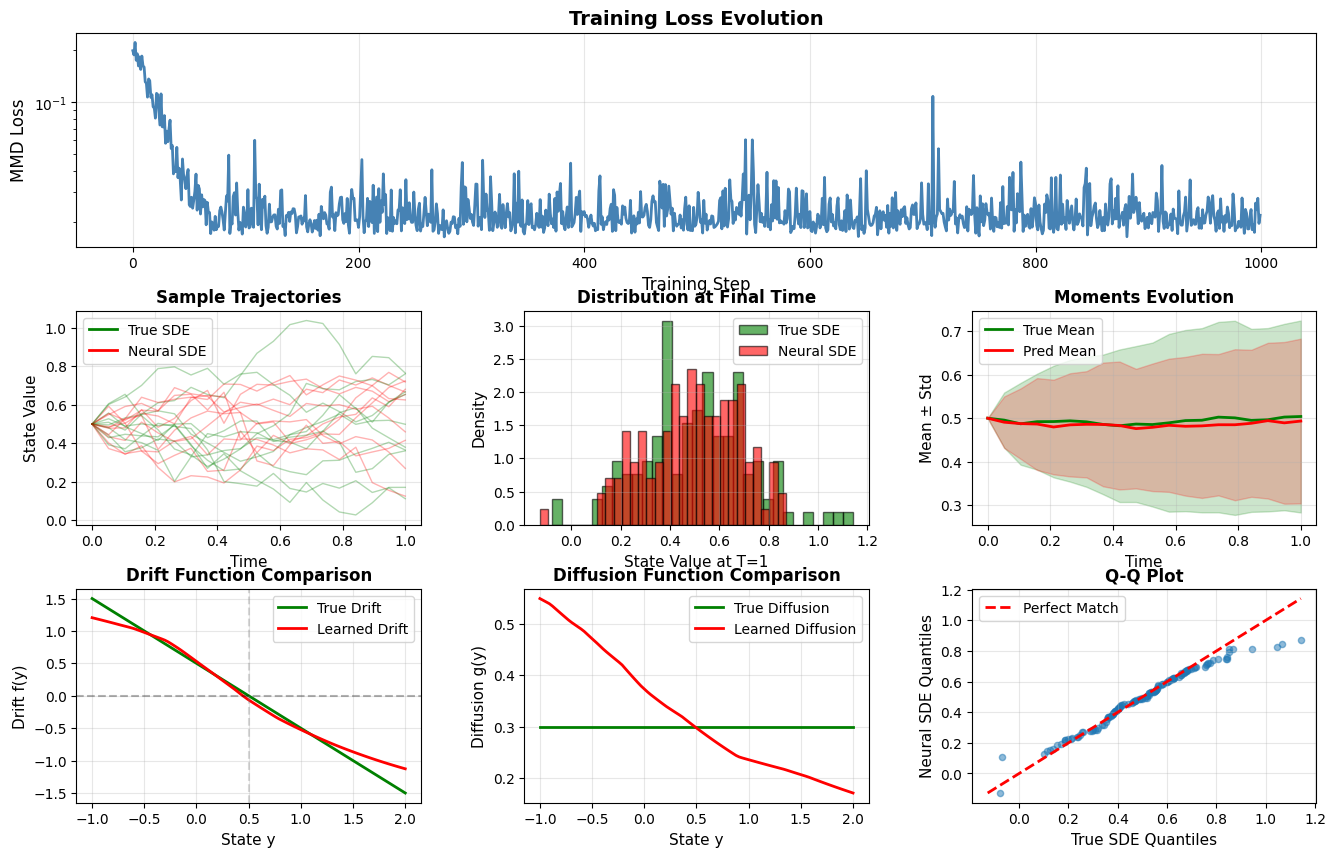


--- Comparing final paths ---
True SDE mean at T: 0.3581
Neural SDE mean at T: 0.5386

 True diffusion g(0.5): 0.3000
Learned diffusion g(0.5): 0.2975


In [20]:
if __name__ == "__main__":
    # set a random seed for reproducibility

    torch.manual_seed(42)
    np.random.seed(42)

main()

Possible improvements:

1. Model blindly prioritizes lowering loss and "cheat" by being too smooth.
   
Fix: Change the Loss Function: Switch from a simple MSE on the paths to a distribution matching loss (like a GAN or Maximum Mean Discrepancy, MMD✅). These losses compare the statistical properties of the generated paths, making it harder for the model to "cheat" by being too smooth.

2. Choice of activation function.
   
Fix: Remove Sigmoid from DiffusionNet: The <code>nn.Sigmoid()</code> activation keeps the output bounded between $(0, 1)$. Since the true $\sigma$ is $0.3$, this isn't strictly an issue, but a <code>nn.Softplus()</code>✅ (output: $(0, \infty)$) is often preferred for diffusion networks as it ensures positivity while allowing larger values.

3. Inadequate training.
   
Fix: Increase Training Time: The training might need more than 500 steps✅, especially with a low learning rate, to fully escape the local minimum that favors smoothness. Increase steps and see if the diffusion value starts climbing.

4. Choice of optimizer.
   
Fix: Try a Different Optimizer: While Adam is standard, exploring different optimizers or adding learning rate scheduling can sometimes help escape smooth local minima. Learning rate scheduler like <code>ReduceLROnPlateau</code> or <code>CosineAnnealingWarmRestarts</code> can be used as well.

5. Size of MLPs. 

Fix: increase <code>hidden_size</code> to 32✅, 64, or bigger.

6. MMD kernel bandwidths. 
   
Fix: if the list of sigmas are not well-tuned to the scale of your data, the MMD metric might be too flat to provide meaningful gradients.